# Obtener datos series temporales de L8 y L9 para experimento

In [1]:
import datacube
import xarray as xr
import rioxarray
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

from odc.ui import DcViewer
from datacube.utils import masking
from datacube.utils.rio import configure_s3_access

In [2]:
from dask.distributed import Client, LocalCluster
cluster = LocalCluster()
client = Client(cluster)

configure_s3_access(aws_unsigned=False, requester_pays=True, client=client)

client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /user/jlopatin/proxy/8787/status,
Dashboard: /user/jlopatin/proxy/8787/status,Workers: 4
Total threads: 8,Total memory: 48.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:46801,Workers: 4
Dashboard: /user/jlopatin/proxy/8787/status,Total threads: 8
Started: Just now,Total memory: 48.00 GiB
Comm: tcp://127.0.0.1:39555,Total threads: 2
Dashboard: /user/jlopatin/proxy/41937/status,Memory: 12.00 GiB
Nanny: tcp://127.0.0.1:35471,


In [3]:
dc = datacube.Datacube(app='Susana_S2')

In [4]:
dc.list_products()

,name,description,license,default_crs,default_resolution
name,,,,,
asf_s1_grd_gamma0,asf_s1_grd_gamma0,Sentinel 1 Radiometrically Terrain Corrected,CC-BY-4.0,EPSG:4326,"(-0.0002, 0.0002)"
asf_s1_rtc_grd_hd,asf_s1_rtc_grd_hd,Sentinel 1 Radiometrically Terrain Corrected,CC-BY-4.0,EPSG:4326,"(-0.0002, 0.0002)"
copernicus_dem_30,copernicus_dem_30,Copernicus 30m Digital Elevation Model (GLO-30),None,EPSG:4326,"(-0.00027777777777778, 0.00027777777777778)"
copernicus_dem_90,copernicus_dem_90,Copernicus 90m Digital Elevation Model (GLO-90),None,None,None
cr2met,cr2met,"CR2MET, a high-resolution precipitation and te...",None,EPSG:4326,"(0.05, 0.05)"
fasat_charlie_ms,fasat_charlie_ms,FASat Charlie TOA multi-spectral data (Sistema...,None,None,None
landcover_chile_2014,landcover_chile_2014,Land Cover de Chile 2014,None,None,None
landsat5_c2l2_sr,landsat5_c2l2_sr,Landsat 5 Collection 2 Level-2 Surface Reflect...,None,None,None
landsat5_c2l2_st,landsat5_c2l2_st,Landsat 5 Collection 2 Level-2 UTM Surface Tem...,CC-BY-4.0,None,None


In [5]:
X = -70.80420255655426
Y = -33.528570396842035

## Land cover

In [6]:
product = 'landcover_chile_2014'
query = {"product": product,
         "x": (X-0.01, X+0.01),
         "y": (Y-0.01, Y+0.01),
         #"time": ("2010-01-01", "2024-01-07"),
         "output_crs": 'EPSG:32719',
         "resolution": (-30,30),
         "group_by": 'solar_day',
         #"dask_chunks": {"x": 2048, "y": 2048},
         "skip_broken_datasets": True}
ds = dc.load(**query).squeeze()
ds

<xarray.Dataset> Size: 30kB
Dimensions:      (y: 76, x: 64)
Coordinates:
    time         datetime64[ns] 8B 2014-12-31
  * y            (y) float64 608B 6.29e+06 6.29e+06 ... 6.288e+06 6.288e+06
  * x            (x) float64 512B 3.315e+05 3.315e+05 ... 3.334e+05 3.334e+05
    spatial_ref  int32 4B 32719
Data variables:
    nivel_1      (y, x) uint16 10kB 400 900 900 900 900 ... 100 100 100 100 300
    nivel_2      (y, x) uint16 10kB 410 930 930 930 930 ... 130 130 130 130 310
    nivel_3      (y, x) uint16 10kB 410 932 932 932 932 ... 130 130 130 130 311
Attributes:
    crs:           epsg:32719
    grid_mapping:  spatial_ref

In [7]:
print('total data dimensions = ', len(ds.x)*len(ds.y))

total data dimensions =  4864


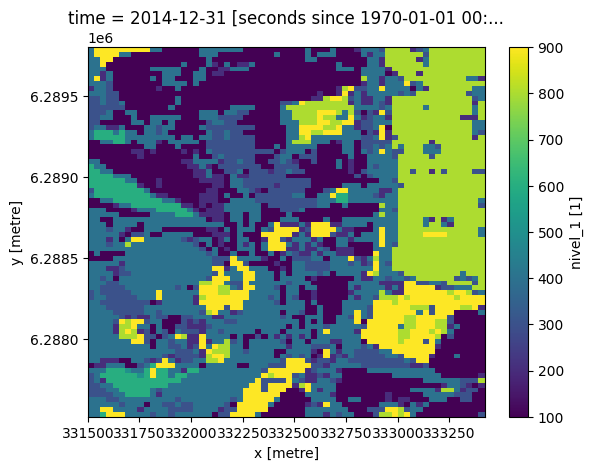

In [8]:
ds.nivel_1.plot()

In [9]:
classes_titles = ['Crops', 'Forests', 'Pastures', 'Shrublands', 'Wetlands', 'Water Bodies', 'Urban', 'Bare Land', 'Ice and Snow', 'Clouds']
classes_id = [100, 200, 300, 400, 500, 600, 800, 900, 1000, 1200]
colors = ['#DA984A', '#4B7A4E', '#8FAE61', '#DBC369', '#7C88C2', '#579BD8', '#B33826', '#A39B90', '#AFA1DC', '#EBEBEB']

Text(0, 0.5, '')

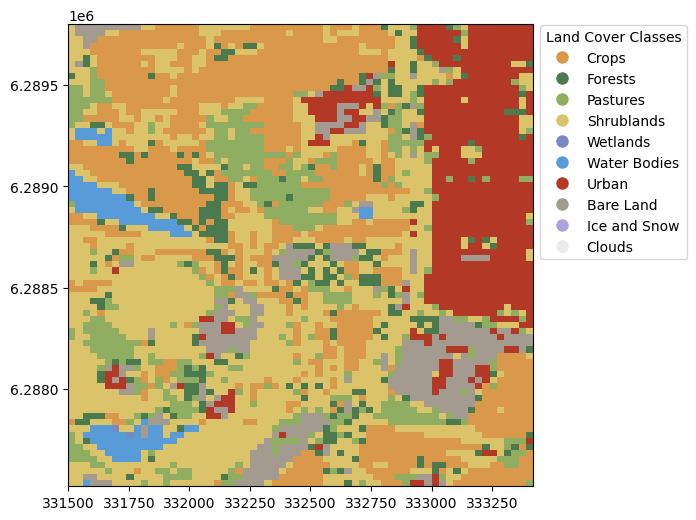

In [10]:
# Create the plot
fig, ax = plt.subplots(figsize=(6, 6))
p = ds.nivel_1.plot(levels=classes_id, colors=colors, ax=ax, add_colorbar=False)

# Create a custom legend
legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label=title, markerfacecolor=color, markersize=10)
                   for title, color in zip(classes_titles, colors)]

# Add the legend outside the plot
ax.legend(handles=legend_elements, title="Land Cover Classes", loc='upper left', bbox_to_anchor=(1, 1.014))
plt.title('')
plt.xlabel('')
plt.ylabel('')

# Show the plot
# plt.savefig('landCover.png', bbox_inches='tight')

In [13]:
ds.rio.to_raster('LC.tif')

In [20]:
# save XY coords stacked
x = ds.stack(z=('y','x')).x.values
y = ds.stack(z=('y','x')).y.values

df_xy = pd.DataFrame({'x': x, 'y': y})
df_xy.to_csv('xy_coords.csv', index=False)

In [20]:
# create 1D data vector of classes
classes = ds.nivel_1.stack(z=('y','x')).values
classes

array([400, 900, 900, ..., 100, 100, 300], dtype=uint16)

## Landsat

In [6]:
product =  ['landsat5_c2l2_sr', 'landsat7_c2l2_sr', "landsat8_c2l2_sr", 'landsat9_c2l2_sr']
query = {"product": product,
         # "measurements": ['red', 'nir08', 'qa_pixel'],
         "x": (X-0.01, X+0.01),
         "y": (Y-0.01, Y+0.01),
         "time": ("2000-01-01", "2023-12-31"),
         "output_crs": 'EPSG:32719',
         "resolution": (-30,30),
         "group_by": 'solar_day',
         "dask_chunks": {"x": 50, "y": 50, 'time':1},
         "skip_broken_datasets": True}
ls = dc.load(**query)
ls

<xarray.Dataset>
Dimensions:        (time: 889, y: 76, x: 64)
Coordinates:
  * time           (time) datetime64[ns] 2000-01-03T14:08:45.250000 ... 2023-...
  * y              (y) float64 6.29e+06 6.29e+06 ... 6.288e+06 6.288e+06
  * x              (x) float64 3.315e+05 3.315e+05 ... 3.334e+05 3.334e+05
    spatial_ref    int32 32719
Data variables:
    blue           (time, y, x) uint16 dask.array<chunksize=(1, 50, 50), meta=np.ndarray>
    green          (time, y, x) uint16 dask.array<chunksize=(1, 50, 50), meta=np.ndarray>
    red            (time, y, x) uint16 dask.array<chunksize=(1, 50, 50), meta=np.ndarray>
    nir08          (time, y, x) uint16 dask.array<chunksize=(1, 50, 50), meta=np.ndarray>
    swir16         (time, y, x) uint16 dask.array<chunksize=(1, 50, 50), meta=np.ndarray>
    swir22         (time, y, x) uint16 dask.array<chunksize=(1, 50, 50), meta=np.ndarray>
    atmos_opacity  (time, y, x) int16 dask.array<chunksize=(1, 50, 50), meta=np.ndarray>
    qa_pixel       (time, y, x) uint16 dask.array<chunksize=(1, 50, 50), meta=np.ndarray>
    qa_radsat      (time, y, x) uint16 dask.array<chunksize=(1, 50, 50), meta=np.ndarray>
    cloud_qa       (time, y, x) uint8 dask.array<chunksize=(1, 50, 50), meta=np.ndarray>
Attributes:
    crs:           EPSG:32719
    grid_mapping:  spatial_ref

In [7]:
list(ls.data_vars.keys())[:-4]

['blue', 'green', 'red', 'nir08', 'swir16', 'swir22']

In [8]:
def mask_and_compute(ds):
    reflectance_bands = list(ds.data_vars.keys())[:-4]
    quality_band = 'qa_pixel'
    good_pixel_flags = {
        "snow": "not_high_confidence",
        "cloud": "not_high_confidence",
        # "cirrus": "not_high_confidence",
        "cloud_shadow": "not_high_confidence",
        # "cloud_confidence": "high",
        # "cloud_shadow_confidence": "high",
        "nodata": False
    }

    cloud_free_mask = masking.make_mask(ds[quality_band], **good_pixel_flags)
    masked = ds[reflectance_bands].where(cloud_free_mask)
    masked.update(masked*0.0000275 + -0.2)
    return masked

In [9]:
masked = mask_and_compute(ls)
masked

<xarray.Dataset>
Dimensions:      (time: 889, y: 76, x: 64)
Coordinates:
  * time         (time) datetime64[ns] 2000-01-03T14:08:45.250000 ... 2023-12...
  * y            (y) float64 6.29e+06 6.29e+06 6.29e+06 ... 6.288e+06 6.288e+06
  * x            (x) float64 3.315e+05 3.315e+05 ... 3.334e+05 3.334e+05
    spatial_ref  int32 32719
Data variables:
    blue         (time, y, x) float32 dask.array<chunksize=(1, 50, 50), meta=np.ndarray>
    green        (time, y, x) float32 dask.array<chunksize=(1, 50, 50), meta=np.ndarray>
    red          (time, y, x) float32 dask.array<chunksize=(1, 50, 50), meta=np.ndarray>
    nir08        (time, y, x) float32 dask.array<chunksize=(1, 50, 50), meta=np.ndarray>
    swir16       (time, y, x) float32 dask.array<chunksize=(1, 50, 50), meta=np.ndarray>
    swir22       (time, y, x) float32 dask.array<chunksize=(1, 50, 50), meta=np.ndarray>
Attributes:
    crs:           EPSG:32719
    grid_mapping:  spatial_ref

/env/lib/python3.10/site-packages/rasterio/warp.py:344: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  _reproject(


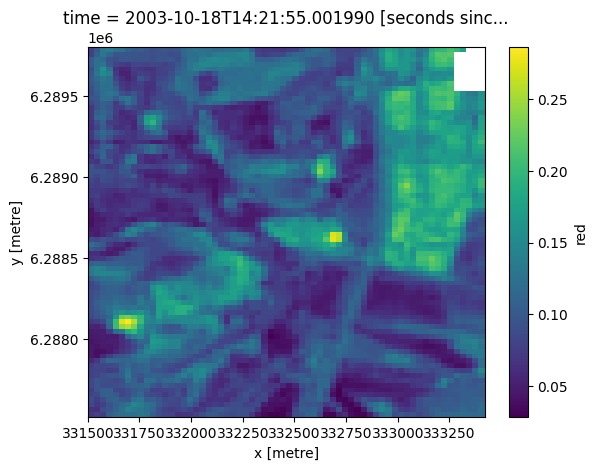

In [10]:
masked.red.isel(time=100).plot()

In [11]:
bands = list(ls.data_vars.keys())
bands

['blue',
 'green',
 'red',
 'nir08',
 'swir16',
 'swir22',
 'atmos_opacity',
 'qa_pixel',
 'qa_radsat',
 'cloud_qa']

In [63]:
masked[bands[i]].isel(time=j).stack(z=('y','x'))

<xarray.DataArray 'blue' (z: 4864)>
dask.array<reshape, shape=(4864,), dtype=float32, chunksize=(1600,), chunktype=numpy.ndarray>
Coordinates:
    time         datetime64[ns] 2011-07-20T14:27:10.967509
    spatial_ref  int32 32719
  * z            (z) object MultiIndex
  * y            (z) float64 6.29e+06 6.29e+06 6.29e+06 ... 6.288e+06 6.288e+06
  * x            (z) float64 3.315e+05 3.315e+05 ... 3.334e+05 3.334e+05

In [64]:
import pandas as pd
from datetime import datetime
from tqdm import tqdm
import warnings

# dates as yyyy-mm-dd
ls_time = ls.time.values
ls_time = ls_time.astype('datetime64[D]')

# Define a mapping dictionary to replace values
class_mapping = {
    100: 'Crops',
    200: 'Forests',
    300: 'Pastures',
    400: 'Shrublands',
    500: 'Wetlands',
    600: 'Water Bodies',
    800: 'Urban',
    900: 'Bare Land',
    1000: 'Ice and Snow',
    1200: 'Clouds'
}



for i in range(len(bands)): # bands  
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        print(bands[i])
        # Create a DataFrame
        data = pd.DataFrame({'classes': classes})
        # Replace values in the 'classes' column using the mapping dictionary
        data['classes'] = data['classes'].map(class_mapping)
        for j in tqdm(range(len(ls.time))): #dates
                # print(str(ls_time[j]))
                band = masked[bands[i]]
                data[str(ls_time[j])] = band.isel(time=j).stack(z=('y','x')).values

        data.to_csv(bands[i]+'.csv', index=False)
        del data

blue


 11%|█         | 99/889 [01:06<07:27,  1.77it/s]/tmp/ipykernel_1054/2080040373.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[str(ls_time[j])] = band.isel(time=j).stack(z=('y','x')).values
 11%|█         | 100/889 [01:06<07:19,  1.80it/s]/tmp/ipykernel_1054/2080040373.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[str(ls_time[j])] = band.isel(time=j).stack(z=('y','x')).values
 11%|█▏        | 101/889 [01:07<07:07,  1.85it/s]/tmp/ipykernel_1054/2080040373.py:37: PerformanceWarning: DataFrame is highly fragme

green


 11%|█         | 99/889 [01:16<09:30,  1.39it/s]/tmp/ipykernel_1054/2080040373.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[str(ls_time[j])] = band.isel(time=j).stack(z=('y','x')).values
 11%|█         | 100/889 [01:17<08:58,  1.46it/s]2024-01-27 19:37:09,630 - distributed.utils_perf - WARNING - full garbage collections took 45% CPU time recently (threshold: 10%)
/tmp/ipykernel_1054/2080040373.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[str(ls_time[j])] = band.isel(time=j).stack(z=('y','x')).values
 11

red


...

swir22


 11%|█         | 99/889 [01:26<11:16,  1.17it/s]/tmp/ipykernel_1054/2080040373.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[str(ls_time[j])] = band.isel(time=j).stack(z=('y','x')).values
 11%|█         | 100/889 [01:27<10:27,  1.26it/s]/tmp/ipykernel_1054/2080040373.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[str(ls_time[j])] = band.isel(time=j).stack(z=('y','x')).values
 11%|█▏        | 101/889 [01:28<11:14,  1.17it/s]/tmp/ipykernel_1054/2080040373.py:37: PerformanceWarning: DataFrame is highly fragme

atmos_opacity


  0%|          | 0/889 [00:00<?, ?it/s]


KeyError: 'atmos_opacity'